# TP7 — Análisis de clubes del fútbol argentino
**Gianfranco Godoy — Dias Maximiliano**  
**Materia:** Análisis de datos en la nube

## Objetivos
Implementar un ETL reproducible con PySpark, Spark SQL y Delta Lake en Databricks Free Edition (cómputo Serverless). Analizar la distribución geográfica y temporal de una muestra de 31 clubes, sin extrapolar al universo nacional.

**Arquitectura:** CSV → Bronze (ingesta) → Silver (limpieza y enriquecimiento) → Gold (indicadores). Los CSV originales permanecen intactos. Las tablas nuevas se administran en Unity Catalog.

## 1. Configuración y exploración del entorno

In [0]:
from pyspark.sql import functions as F
from pyspark.sql.types import StructType, StructField, StringType
import matplotlib.pyplot as plt

BASE = "/Volumes/workspace/default/tp_volume/"
DB = "workspace.tp7_futbol_v6"
ANIO_REFERENCIA = 2026
spark.sql(f"CREATE SCHEMA IF NOT EXISTS {DB}")
print("Hola Databricks — entorno inicializado")
display(spark.sql("SELECT current_catalog() AS catalogo, current_schema() AS esquema, current_date() AS fecha"))

Hola Databricks — entorno inicializado


catalogo,esquema,fecha
workspace,default,2026-11-27


In [0]:
display(dbutils.fs.ls(BASE))

path,name,size,modificationTime
dbfs:/Volumes/workspace/default/tp_volume/equipos_delta/,equipos_delta/,0,1795739657758
dbfs:/Volumes/workspace/default/tp_volume/equipos_futbol_argentino.csv,equipos_futbol_argentino.csv,1494,1793628356000
dbfs:/Volumes/workspace/default/tp_volume/provincias_regiones.csv,provincias_regiones.csv,164,1793628356000


## 2. Bronze — extracción y almacenamiento
Se utilizan esquemas explícitos de texto para conservar los valores antes de convertir tipos. El CSV sigue siendo la fuente original; la tabla Bronze conserva filas repetidas y campos ausentes. La ampliación V6 se ingiere por separado con su fuente oficial; no altera el CSV ni Bronze original. La ingesta es una fotografía reemplazable de la muestra, no un historial incremental.

In [0]:
def leer_csv(nombre, columnas):
    esquema = StructType([StructField(x, StringType(), True) for x in columnas])
    return (spark.read.option("header", True).option("encoding", "UTF-8")
            .option("mode", "FAILFAST").option("enforceSchema", False)
            .schema(esquema).csv(BASE + nombre))

def guardar(df, nombre):
    tabla = f"{DB}.{nombre}"
    df.write.format("delta").mode("overwrite").option("overwriteSchema", "true").saveAsTable(tabla)
    return spark.table(tabla)

def validar_integridad(a, b):
    assert a.dtypes == b.dtypes, "Tipos o columnas diferentes"
    assert a.count() == b.count(), "Cantidad diferente"
    assert a.exceptAll(b).count() == 0 and b.exceptAll(a).count() == 0, "Contenido diferente"

raw_e = leer_csv("equipos_futbol_argentino.csv", ["equipo", "ciudad", "provincia", "anio_fundacion", "estadio"])
raw_p = leer_csv("provincias_regiones.csv", ["provincia", "region"])
assert raw_e.count() == 32 and raw_p.count() == 8
be = guardar(raw_e.withColumn("archivo_origen", F.lit("equipos_futbol_argentino.csv")), "bronze_equipos")
bp = guardar(raw_p.withColumn("archivo_origen", F.lit("provincias_regiones.csv")), "bronze_provincias")
validar_integridad(raw_e, be.select(*raw_e.columns))
validar_integridad(raw_p, bp.select(*raw_p.columns))
altas = spark.createDataFrame([("Gimnasia y Esgrima de Mendoza", "Mendoza", "Mendoza", "1908", "Víctor Antonio Legrotaglie", "https://www.ligaprofesional.ar/clubes/gimnasia-de-mendoza/")], ", ".join([x+" string" for x in raw_e.columns])+", fuente_alta string")
assert altas.count() == 1
assert altas.join(raw_e, "equipo", "inner").count() == 0
ba = guardar(altas, "bronze_altas")
validar_integridad(altas, ba)
print("[OK] Alta V6: 1 club adicional con fuente oficial")
print("[OK] Bronze: 32 registros de equipos y 8 jurisdicciones; integridad verificada")

[OK] Alta V6: 1 club adicional con fuente oficial
[OK] Bronze: 32 registros de equipos y 8 jurisdicciones; integridad verificada


In [0]:
display(be)

equipo,ciudad,provincia,anio_fundacion,estadio,archivo_origen
Boca Juniors,Buenos Aires,CABA,1905,La Bombonera,equipos_futbol_argentino.csv
River Plate,Buenos Aires,CABA,1901,Monumental,equipos_futbol_argentino.csv
Racing Club,Avellaneda,Buenos Aires,1903,Presidente Perón,equipos_futbol_argentino.csv
Independiente,Avellaneda,Buenos Aires,1905,Libertadores de América,equipos_futbol_argentino.csv
San Lorenzo,Buenos Aires,CABA,1908,Nuevo Gasómetro,equipos_futbol_argentino.csv
Estudiantes de La Plata,La Plata,Buenos Aires,null,null,equipos_futbol_argentino.csv
Gimnasia y Esgrima La Plata,La Plata,Buenos Aires,1887,null,equipos_futbol_argentino.csv
Vélez Sarsfield,Buenos Aires,CABA,1910,José Amalfitani,equipos_futbol_argentino.csv
Newell's Old Boys,Rosario,Santa Fe,1903,null,equipos_futbol_argentino.csv
Rosario Central,Rosario,Santa Fe,1889,null,equipos_futbol_argentino.csv


In [0]:
display(bp)

provincia,region,archivo_origen
CABA,Centro,provincias_regiones.csv
Buenos Aires,Centro,provincias_regiones.csv
Santa Fe,Centro,provincias_regiones.csv
Córdoba,Centro,provincias_regiones.csv
Mendoza,Cuyo,provincias_regiones.csv
San Juan,Cuyo,provincias_regiones.csv
Tucumán,Noroeste,provincias_regiones.csv
Santiago del Estero,Noroeste,provincias_regiones.csv


In [0]:
be.printSchema()
be.createOrReplaceTempView("tp7_equipos_raw")
display(spark.sql("SELECT provincia, COUNT(*) AS filas FROM tp7_equipos_raw GROUP BY provincia ORDER BY filas DESC"))

root
 |-- equipo: string (nullable = true)
 |-- ciudad: string (nullable = true)
 |-- provincia: string (nullable = true)
 |-- anio_fundacion: string (nullable = true)
 |-- estadio: string (nullable = true)
 |-- archivo_origen: string (nullable = true)



provincia,filas
CABA,10
Buenos Aires,10
Santa Fe,4
Mendoza,2
Córdoba,2
null,1
Tucumán,1
Santiago del Estero,1
San Juan,1


In [0]:
def perfil(df, etapa):
    return df.agg(*[F.sum(F.when(F.col(x).isNull() | (F.trim(F.col(x).cast("string")) == ""), 1).otherwise(0)).alias(x) for x in df.columns]).withColumn("etapa", F.lit(etapa))

display(perfil(raw_e, "Bronze"))
display(raw_e.groupBy(*raw_e.columns).count().filter(F.col("count") > 1))

equipo,ciudad,provincia,anio_fundacion,estadio,etapa
0,0,1,1,24,Bronze


equipo,ciudad,provincia,anio_fundacion,estadio,count
Boca Juniors,Buenos Aires,CABA,1905,La Bombonera,2
San Lorenzo,Buenos Aires,CABA,1908,Nuevo Gasómetro,2


## 3. Silver — transformación y calidad
Se eliminan duplicados exactos y se convierten años a enteros. Los faltantes se completan con referencias institucionales y directorios secundarios. Se conservan valores originales y fuentes por campo. Para estadios se prioriza el recinto propio o histórico asociado al club, no necesariamente la sede de cada partido.


In [0]:
def normalizar(df):
    return df.select(*[F.when(F.trim(F.col(x)) == "", F.lit(None)).otherwise(F.trim(F.col(x))).alias(x) for x in df.columns])

base_limpia = normalizar(be.select(*raw_e.columns)).dropDuplicates()
assert base_limpia.count() == 30
limpio = base_limpia.unionByName(normalizar(ba.select(*raw_e.columns)))
assert limpio.count() == 31
assert limpio.groupBy("equipo").count().filter("count > 1").count() == 0
correcciones = spark.createDataFrame([
    ("Estudiantes de La Plata", None, 1905, "Jorge Luis Hirschi", None, "https://estudiantesdelaplata.com/historia/", "https://estudiantesdelaplata.com/estadio/"),
    ("Instituto", "Córdoba", None, "Juan Domingo Perón", "https://institutoacc.com.ar/index.php/instalaciones/", None, "https://institutoacc.com.ar/index.php/instalaciones/"),
    ('Gimnasia y Esgrima La Plata', None, None, 'Juan Carmelo Zerillo', None, None, 'https://footballclubsmap.com/countries/argentina/liga-profesional/es/'),
    ("Newell's Old Boys", None, None, 'Marcelo Bielsa', None, None, 'https://footballclubsmap.com/countries/argentina/liga-profesional/es/'),
    ('Rosario Central', None, None, 'Gigante de Arroyito', None, None, 'https://footballtripper.com/argentina/'),
    ('Talleres', None, None, 'Francisco Cabasés', None, None, 'https://ligasargentinas.com.ar/maps'),
    ('Belgrano', None, None, 'Julio César Villagra', None, None, 'https://footballclubsmap.com/countries/argentina/liga-profesional/es/'),
    ('Lanús', None, None, 'Ciudad de Lanús - Néstor Díaz Pérez', None, None, 'https://footballclubsmap.com/countries/argentina/liga-profesional/es/'),
    ('Banfield', None, None, 'Florencio Solá', None, None, 'https://footballclubsmap.com/countries/argentina/liga-profesional/es/'),
    ('Huracán', None, None, 'Tomás Adolfo Ducó', None, None, 'https://footballclubsmap.com/countries/argentina/liga-profesional/es/'),
    ('Argentinos Juniors', None, None, 'Diego Armando Maradona', None, None, 'https://footballclubsmap.com/countries/argentina/liga-profesional/es/'),
    ('Defensa y Justicia', None, None, 'Norberto Tito Tomaghello', None, None, 'https://footballclubsmap.com/countries/argentina/liga-profesional/es/'),
    ('Platense', None, None, 'Ciudad de Vicente López', None, None, 'https://footballclubsmap.com/countries/argentina/liga-profesional/es/'),
    ('Tigre', None, None, 'José Dellagiovanna', None, None, 'https://footballclubsmap.com/countries/argentina/liga-profesional/es/'),
    ('Godoy Cruz', None, None, 'Feliciano Gambarte', None, None, 'https://ligasargentinas.com.ar/maps'),
    ('Independiente Rivadavia', None, None, 'Juan Bautista Gargantini', None, None, 'https://footballclubsmap.com/countries/argentina/liga-profesional/es/'),
    ('Unión', None, None, '15 de Abril', None, None, 'https://footballclubsmap.com/countries/argentina/liga-profesional/es/'),
    ('Colón', None, None, 'Brigadier General Estanislao López', None, None, 'https://ligasargentinas.com.ar/maps'),
    ('Atlético Tucumán', None, None, 'Monumental José Fierro', None, None, 'https://footballclubsmap.com/countries/argentina/liga-profesional/es/'),
    ('Sarmiento', None, None, 'Eva Perón', None, None, 'https://footballclubsmap.com/countries/argentina/liga-profesional/es/'),
    ('Central Córdoba', None, None, 'Alfredo Terrera', None, None, 'https://ligasargentinas.com.ar/maps'),
    ('Barracas Central', None, None, 'Claudio Chiqui Tapia', None, None, 'https://footballclubsmap.com/countries/argentina/liga-profesional/es/'),
    ('San Martín de San Juan', None, None, 'Hilario Sánchez Rodríguez', None, None, 'https://www.ligaprofesional.ar/clubes/smsj/'),
    ('Deportivo Riestra', None, None, 'Guillermo Laza', None, None, 'https://footballclubsmap.com/countries/argentina/liga-profesional/es/')
], "equipo string, provincia_correccion string, anio_correccion int, estadio_correccion string, fuente_provincia string, fuente_anio string, fuente_estadio string")
assert correcciones.groupBy("equipo").count().filter("count > 1").count() == 0
assert correcciones.join(limpio, "equipo", "left_anti").count() == 0
correcciones = guardar(correcciones, "bronze_correcciones")
limpio = (limpio.join(correcciones, "equipo", "left")
    .withColumn("provincia_original", F.col("provincia"))
    .withColumn("estadio_original", F.col("estadio"))
    .withColumn("anio_fundacion_original", F.col("anio_fundacion"))
    .withColumn("provincia_inferida", F.lit(False))
    .withColumn("provincia_corregida", F.col("provincia").isNull() & F.col("provincia_correccion").isNotNull())
    .withColumn("provincia", F.coalesce("provincia", "provincia_correccion"))
    .withColumn("estadio", F.coalesce("estadio", "estadio_correccion"))
    .withColumn("anio_fundacion", F.coalesce(F.expr("try_cast(anio_fundacion as int)"), F.when(F.col("anio_fundacion_original").isNull(), F.col("anio_correccion"))))
    .drop("provincia_correccion", "anio_correccion", "estadio_correccion")
    .join(ba.select("equipo", "fuente_alta"), "equipo", "left"))
assert limpio.filter("anio_fundacion IS NULL").count() == 0
assert limpio.filter("estadio IS NULL").count() == 0
assert limpio.filter("provincia_corregida").count() == 1
assert limpio.filter("estadio_original IS NULL AND estadio IS NOT NULL").count() == 24
assert limpio.filter(F.col("anio_fundacion_original").isNotNull() & F.col("anio_fundacion").isNull()).count() == 0
assert limpio.filter((F.col("anio_fundacion") < 1800) | (F.col("anio_fundacion") > ANIO_REFERENCIA)).count() == 0
provincias = normalizar(bp.select(*raw_p.columns))
assert provincias.filter(F.col("provincia").isNull() | F.col("region").isNull()).count() == 0
assert provincias.groupBy("provincia").count().filter("count > 1").count() == 0
sin_match = limpio.join(provincias, "provincia", "left_anti")
assert sin_match.count() == 0, "Existen provincias sin correspondencia"
silver_df = (limpio.join(provincias, "provincia", "left")
    .withColumn("antiguedad", F.lit(ANIO_REFERENCIA) - F.col("anio_fundacion"))
    .withColumn("decada", (F.floor(F.col("anio_fundacion") / 10)*10).cast("int"))
    .withColumn("epoca", F.when(F.col("anio_fundacion").isNull(), "Sin dato").when(F.col("anio_fundacion") < 1900, "Siglo XIX").otherwise("Siglo XX o posterior")))
assert silver_df.count() == limpio.count()
assert silver_df.filter(F.col("equipo").isNull() | F.col("ciudad").isNull() | F.col("region").isNull()).count() == 0
silver = guardar(silver_df, "silver_equipos")
validar_integridad(silver_df, silver)
nuevo = silver.filter(F.col("equipo") == "Gimnasia y Esgrima de Mendoza")
assert nuevo.count() == 1
assert nuevo.filter("provincia = 'Mendoza' AND ciudad = 'Mendoza' AND region = 'Cuyo' AND anio_fundacion = 1908 AND antiguedad = 118 AND decada = 1900 AND estadio = 'Víctor Antonio Legrotaglie' AND fuente_alta IS NOT NULL").count() == 1
assert silver.count() == 31
print("[OK] Silver: 31 clubes únicos; JOIN sin pérdidas; integridad verificada")

[OK] Silver: 31 clubes únicos; JOIN sin pérdidas; integridad verificada


In [0]:
display(silver.orderBy("equipo"))

provincia,equipo,ciudad,anio_fundacion,estadio,fuente_provincia,fuente_anio,fuente_estadio,provincia_original,estadio_original,anio_fundacion_original,provincia_inferida,provincia_corregida,fuente_alta,region,antiguedad,decada,epoca
CABA,Argentinos Juniors,Buenos Aires,1904,Diego Armando Maradona,null,null,https://footballclubsmap.com/countries/argentina/liga-profesional/es/,CABA,null,1904,false,false,null,Centro,122,1900,Siglo XX o posterior
Tucumán,Atlético Tucumán,San Miguel de Tucumán,1902,Monumental José Fierro,null,null,https://footballclubsmap.com/countries/argentina/liga-profesional/es/,Tucumán,null,1902,false,false,null,Noroeste,124,1900,Siglo XX o posterior
Buenos Aires,Banfield,Banfield,1896,Florencio Solá,null,null,https://footballclubsmap.com/countries/argentina/liga-profesional/es/,Buenos Aires,null,1896,false,false,null,Centro,130,1890,Siglo XIX
CABA,Barracas Central,Buenos Aires,1904,Claudio Chiqui Tapia,null,null,https://footballclubsmap.com/countries/argentina/liga-profesional/es/,CABA,null,1904,false,false,null,Centro,122,1900,Siglo XX o posterior
Córdoba,Belgrano,Córdoba,1905,Julio César Villagra,null,null,https://footballclubsmap.com/countries/argentina/liga-profesional/es/,Córdoba,null,1905,false,false,null,Centro,121,1900,Siglo XX o posterior
CABA,Boca Juniors,Buenos Aires,1905,La Bombonera,null,null,null,CABA,La Bombonera,1905,false,false,null,Centro,121,1900,Siglo XX o posterior
Santiago del Estero,Central Córdoba,Santiago del Estero,1919,Alfredo Terrera,null,null,https://ligasargentinas.com.ar/maps,Santiago del Estero,null,1919,false,false,null,Noroeste,107,1910,Siglo XX o posterior
Santa Fe,Colón,Santa Fe,1905,Brigadier General Estanislao López,null,null,https://ligasargentinas.com.ar/maps,Santa Fe,null,1905,false,false,null,Centro,121,1900,Siglo XX o posterior
Buenos Aires,Defensa y Justicia,Florencio Varela,1935,Norberto Tito Tomaghello,null,null,https://footballclubsmap.com/countries/argentina/liga-profesional/es/,Buenos Aires,null,1935,false,false,null,Centro,91,1930,Siglo XX o posterior
CABA,Deportivo Riestra,Buenos Aires,1931,Guillermo Laza,null,null,https://footballclubsmap.com/countries/argentina/liga-profesional/es/,CABA,null,1931,false,false,null,Centro,95,1930,Siglo XX o posterior


In [0]:
display(nuevo)
display(silver.filter(F.col("fuente_anio").isNotNull() | F.col("provincia_corregida") | F.col("fuente_estadio").isNotNull()).select("equipo", "provincia", "provincia_corregida", "anio_fundacion", "estadio", "fuente_anio", "fuente_provincia", "fuente_estadio"))
display(silver.filter(F.col("anio_fundacion") < 1905).select("equipo", "anio_fundacion").orderBy("anio_fundacion"))

provincia,equipo,ciudad,anio_fundacion,estadio,fuente_provincia,fuente_anio,fuente_estadio,provincia_original,estadio_original,anio_fundacion_original,provincia_inferida,provincia_corregida,fuente_alta,region,antiguedad,decada,epoca
Mendoza,Gimnasia y Esgrima de Mendoza,Mendoza,1908,Víctor Antonio Legrotaglie,null,null,null,Mendoza,Víctor Antonio Legrotaglie,1908,false,false,https://www.ligaprofesional.ar/clubes/gimnasia-de-mendoza/,Cuyo,118,1900,Siglo XX o posterior


equipo,provincia,provincia_corregida,anio_fundacion,estadio,fuente_anio,fuente_provincia,fuente_estadio
Central Córdoba,Santiago del Estero,false,1919,Alfredo Terrera,null,null,https://ligasargentinas.com.ar/maps
Atlético Tucumán,Tucumán,false,1902,Monumental José Fierro,null,null,https://footballclubsmap.com/countries/argentina/liga-profesional/es/
Argentinos Juniors,CABA,false,1904,Diego Armando Maradona,null,null,https://footballclubsmap.com/countries/argentina/liga-profesional/es/
Tigre,Buenos Aires,false,1902,José Dellagiovanna,null,null,https://footballclubsmap.com/countries/argentina/liga-profesional/es/
San Martín de San Juan,San Juan,false,1907,Hilario Sánchez Rodríguez,null,null,https://www.ligaprofesional.ar/clubes/smsj/
Estudiantes de La Plata,Buenos Aires,false,1905,Jorge Luis Hirschi,https://estudiantesdelaplata.com/historia/,null,https://estudiantesdelaplata.com/estadio/
Gimnasia y Esgrima La Plata,Buenos Aires,false,1887,Juan Carmelo Zerillo,null,null,https://footballclubsmap.com/countries/argentina/liga-profesional/es/
Godoy Cruz,Mendoza,false,1921,Feliciano Gambarte,null,null,https://ligasargentinas.com.ar/maps
Newell's Old Boys,Santa Fe,false,1903,Marcelo Bielsa,null,null,https://footballclubsmap.com/countries/argentina/liga-profesional/es/
Belgrano,Córdoba,false,1905,Julio César Villagra,null,null,https://footballclubsmap.com/countries/argentina/liga-profesional/es/


equipo,anio_fundacion
Gimnasia y Esgrima La Plata,1887
Rosario Central,1889
Banfield,1896
River Plate,1901
Atlético Tucumán,1902
Tigre,1902
Newell's Old Boys,1903
Racing Club,1903
Argentinos Juniors,1904
Barracas Central,1904


## 4. Gold — agregaciones e indicadores
Los promedios utilizan únicamente antigüedades conocidas. Se informa el denominador válido para evitar interpretaciones engañosas.

In [0]:
def resumen(dimension):
    return silver.groupBy(dimension).agg(F.count("*").alias("cantidad_clubes"), F.count("antiguedad").alias("anios_conocidos"), F.round(F.avg("antiguedad"), 2).alias("antiguedad_promedio"))

gp = guardar(resumen("provincia"), "gold_clubes_provincia")
gr = guardar(resumen("region"), "gold_clubes_region")
gd = guardar(silver.filter(F.col("decada").isNotNull()).groupBy("decada").agg(F.count("*").alias("clubes_fundados")), "gold_clubes_decada")
calidad = spark.createDataFrame([
    ("Filas originales", raw_e.count()),
    ("Altas verificadas", ba.count()),
    ("Clubes únicos", silver.count()),
    ("Duplicados eliminados", raw_e.count()-base_limpia.count()),
    ("Provincias verificadas y completadas", silver.filter("provincia_corregida").count()),
    ("Estadios completados", silver.filter("estadio_original IS NULL AND estadio IS NOT NULL").count()),
    ("Años faltantes", silver.filter("anio_fundacion IS NULL").count()),
    ("Estadios faltantes", silver.filter("estadio IS NULL").count())
], ["indicador", "valor"])
gq = guardar(calidad, "gold_calidad_datos")
assert gp.agg(F.sum("cantidad_clubes")).first()[0] == silver.count()
assert gr.agg(F.sum("cantidad_clubes")).first()[0] == silver.count()
assert gd.agg(F.sum("clubes_fundados")).first()[0] == silver.filter("anio_fundacion IS NOT NULL").count()
assert raw_e.count() + ba.count() - (raw_e.count()-base_limpia.count()) == silver.count()
assert gr.filter("region = 'Cuyo'").first()["cantidad_clubes"] == 4
assert gp.filter("provincia = 'Mendoza'").first()["cantidad_clubes"] == 3
display(gq)
print("[OK] Gold: agregaciones reconciliadas con Silver")

indicador,valor
Filas originales,32
Altas verificadas,1
Clubes únicos,31
Duplicados eliminados,2
Provincias verificadas y completadas,1
Estadios completados,24
Años faltantes,0
Estadios faltantes,0


[OK] Gold: agregaciones reconciliadas con Silver


In [0]:
display(spark.sql(f"SELECT * FROM {DB}.gold_clubes_provincia ORDER BY cantidad_clubes DESC, provincia"))
display(spark.sql(f"SELECT * FROM {DB}.gold_clubes_region ORDER BY cantidad_clubes DESC, region"))

provincia,cantidad_clubes,anios_conocidos,antiguedad_promedio
Buenos Aires,10,10,119.6
CABA,8,8,117.13
Santa Fe,4,4,125.0
Córdoba,3,3,114.0
Mendoza,3,3,112.0
San Juan,1,1,119.0
Santiago del Estero,1,1,107.0
Tucumán,1,1,124.0


region,cantidad_clubes,anios_conocidos,antiguedad_promedio
Centro,25,25,119.0
Cuyo,4,4,113.75
Noroeste,2,2,115.5


In [0]:
display(spark.sql(f"SELECT equipo, anio_fundacion, antiguedad FROM {DB}.silver_equipos WHERE anio_fundacion IS NOT NULL ORDER BY anio_fundacion, equipo LIMIT 10"))

equipo,anio_fundacion,antiguedad
Gimnasia y Esgrima La Plata,1887,139
Rosario Central,1889,137
Banfield,1896,130
River Plate,1901,125
Atlético Tucumán,1902,124
Tigre,1902,124
Newell's Old Boys,1903,123
Racing Club,1903,123
Argentinos Juniors,1904,122
Barracas Central,1904,122


## 5. Delta Lake — integridad, historial y Time Travel
Se conserva una tabla de demostración separada. Primero se escribe el año original de Estudiantes (nulo), luego se aplica la corrección verificada. Se consultan las dos versiones por su número real, incluso si se repite el notebook.

In [0]:
demo = f"{DB}.demo_time_travel"
antes = silver.filter(F.col("equipo") == "Estudiantes de La Plata").select("equipo", F.expr("try_cast(anio_fundacion_original as int)").alias("anio_fundacion"))
guardar(antes, "demo_time_travel")
def ultima_version(tabla):
    return spark.sql(f"DESCRIBE HISTORY {tabla}").agg(F.max("version")).first()[0]
v_antes = ultima_version(demo)
spark.sql(f"UPDATE {demo} SET anio_fundacion = 1905 WHERE equipo = 'Estudiantes de La Plata'")
v_despues = ultima_version(demo)
a = spark.sql(f"SELECT * FROM {demo} VERSION AS OF {v_antes}")
b = spark.sql(f"SELECT * FROM {demo} VERSION AS OF {v_despues}")
assert v_despues > v_antes
assert a.count() == b.count() == 1
assert a.first()["anio_fundacion"] is None and b.first()["anio_fundacion"] == 1905
display(a.withColumn("version", F.lit(v_antes)).unionByName(b.withColumn("version", F.lit(v_despues))))
display(spark.sql(f"DESCRIBE HISTORY {demo}").select("version", "timestamp", "operation"))
print(f"[OK] Time Travel: versiones {v_antes} y {v_despues} verificadas")

equipo,anio_fundacion,version
Estudiantes de La Plata,null,0
Estudiantes de La Plata,1905,1


version,timestamp,operation
1,2026-11-27T00:35:41.624Z,UPDATE
0,2026-11-27T00:35:37.299Z,CREATE OR REPLACE TABLE AS SELECT


[OK] Time Travel: versiones 0 y 1 verificadas


## 6. Visualización y análisis
Solo se convierten a Pandas las pequeñas tablas agregadas para graficar, no el dataset completo.

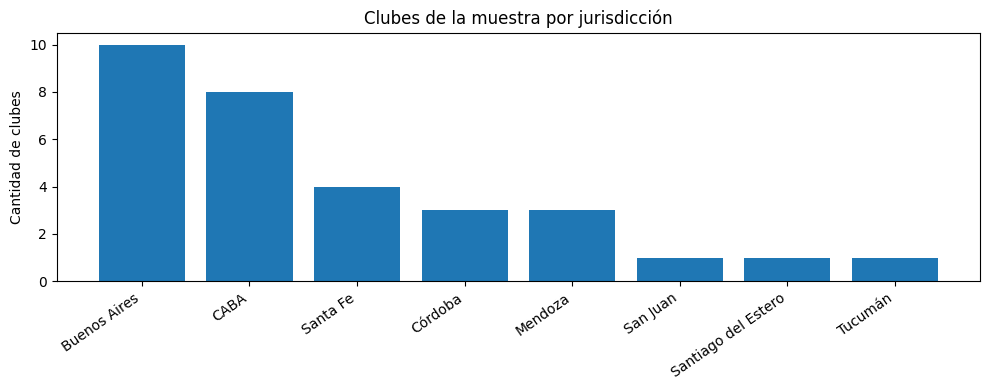

In [0]:
p = gp.orderBy(F.desc("cantidad_clubes"), "provincia").toPandas()
plt.figure(figsize=(10, 4))
plt.bar(p["provincia"], p["cantidad_clubes"])
plt.title("Clubes de la muestra por jurisdicción")
plt.ylabel("Cantidad de clubes")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

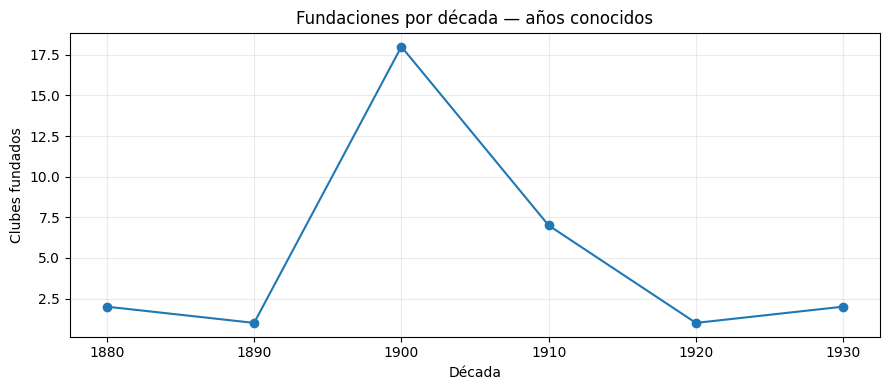

In [0]:
d = gd.orderBy("decada").toPandas().set_index("decada")
d = d.reindex(range(int(d.index.min()), int(d.index.max())+10, 10), fill_value=0)
plt.figure(figsize=(9, 4))
plt.plot(d.index, d["clubes_fundados"], marker="o")
plt.title("Fundaciones por década — años conocidos")
plt.xlabel("Década")
plt.ylabel("Clubes fundados")
plt.grid(alpha=.25)
plt.tight_layout()
plt.show()

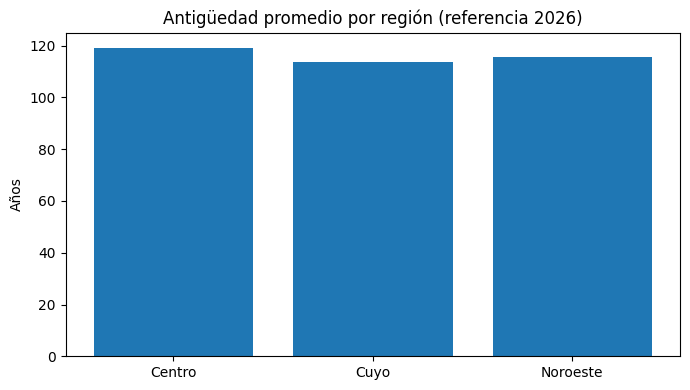

In [0]:
r = gr.orderBy(F.desc("cantidad_clubes"), "region").toPandas()
plt.figure(figsize=(7, 4))
plt.bar(r["region"], r["antiguedad_promedio"])
plt.title(f"Antigüedad promedio por región (referencia {ANIO_REFERENCIA})")
plt.ylabel("Años")
plt.tight_layout()
plt.show()

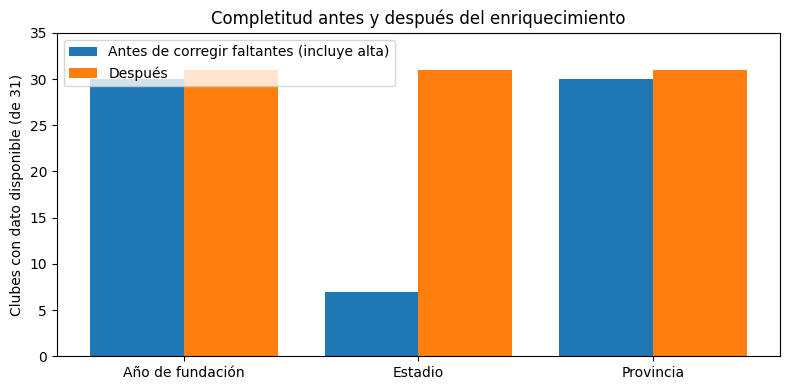

In [0]:
campos = ["Año de fundación", "Estadio", "Provincia"]
antes = [limpio.filter("anio_fundacion_original IS NOT NULL").count(), limpio.filter("estadio_original IS NOT NULL").count(), limpio.filter("provincia_original IS NOT NULL").count()]
despues = [silver.filter(f"{x} IS NOT NULL").count() for x in ["anio_fundacion", "estadio", "provincia"]]
x = list(range(3))
plt.figure(figsize=(8,4))
plt.bar([i-.2 for i in x], antes, width=.4, label="Antes de corregir faltantes (incluye alta)")
plt.bar([i+.2 for i in x], despues, width=.4, label="Después")
plt.xticks(x, campos)
plt.ylim(0, silver.count()+4)
plt.ylabel(f"Clubes con dato disponible (de {silver.count()})")
plt.title("Completitud antes y después del enriquecimiento")
plt.legend()
plt.tight_layout()
plt.show()

## 7. Resultados y conclusiones
Las conclusiones se calculan a partir de las tablas finales para evitar cifras desactualizadas.

In [0]:
total = silver.count()
principal = gr.orderBy(F.desc("cantidad_clubes"), "region").first()
max_decada = gd.orderBy(F.desc("clubes_fundados"), "decada").first()
conocidos = silver.filter("anio_fundacion IS NOT NULL").count()
print(f"Se obtuvieron {total} clubes únicos: {raw_e.count()} filas originales, {raw_e.count()-base_limpia.count()} duplicados eliminados y {ba.count()} alta verificada.")
print(f"Mendoza: {gp.filter(F.col('provincia') == 'Mendoza').first()['cantidad_clubes']} clubes; Cuyo: {gr.filter(F.col('region') == 'Cuyo').first()['cantidad_clubes']} clubes.")
print(f"La región {principal.region} reúne {principal.cantidad_clubes} clubes ({principal.cantidad_clubes/total:.1%} de la muestra).")
print(f"La década de {max_decada.decada} registra {max_decada.clubes_fundados} fundaciones, entre {conocidos} clubes con año conocido.")
print(f"Años desconocidos: {total-conocidos}. Estadios desconocidos: {silver.filter('estadio IS NULL').count()}.")
print("[OK] PIPELINE COMPLETO — Bronze, Silver, Gold y Delta Lake validados")

Se obtuvieron 31 clubes únicos: 32 filas originales, 2 duplicados eliminados y 1 alta verificada.
Mendoza: 3 clubes; Cuyo: 4 clubes.
La región Centro reúne 25 clubes (80.6% de la muestra).
La década de 1900 registra 18 fundaciones, entre 31 clubes con año conocido.
Años desconocidos: 0. Estadios desconocidos: 0.
[OK] PIPELINE COMPLETO — Bronze, Silver, Gold y Delta Lake validados


## 8. Limitaciones y reproducibilidad
V6 incorpora Gimnasia y Esgrima de Mendoza (fundado el 30/08/1908, estadio Víctor Antonio Legrotaglie), participante de Primera División en 2026 tras el ascenso de 2025. Fuente: [Liga Profesional de Fútbol de AFA](https://www.ligaprofesional.ar/clubes/gimnasia-de-mendoza/) y [Ligas Argentinas](https://ligasargentinas.com.ar/club/gimnasia-mendoza). El alta se registra en bronze_altas y su URL se conserva en Silver.

La muestra no es un censo ni una nómina oficial de una temporada. La completitud no garantiza exactitud: los campos originales no fueron auditados individualmente. Los estadios añadidos son recintos asociados al club; Talleres y Central Córdoba también pueden utilizar otros estadios. La antigüedad se aproxima por diferencia de años respecto de 2026.

Referencias de V4 conservadas: [Estudiantes historia](https://estudiantesdelaplata.com/historia/), [Estudiantes estadio](https://estudiantesdelaplata.com/estadio/), [Instituto instalaciones](https://institutoacc.com.ar/index.php/instalaciones/). Referencias adicionales consultadas el 26/11/2026: [FootballClubsMap](https://footballclubsmap.com/countries/argentina/liga-profesional/es/), [Ligas Argentinas](https://ligasargentinas.com.ar/maps), [Football Tripper](https://footballtripper.com/argentina/), [Liga Profesional — San Martín](https://www.ligaprofesional.ar/clubes/smsj/). Los directorios son fuentes secundarias, no certificados oficiales.

Para reproducir: usar los dos CSV originales en el volumen configurado, conectar Serverless y ejecutar en orden. La dimensión de correcciones está incluida en el código y se persiste en Delta. Las escrituras reemplazan exclusivamente las tablas de `workspace.tp7_futbol_v6`.
